<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp8b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')

zip_path = "/content/drive/MyDrive/deeplearning/mini_speech_commands.zip"

print(os.path.exists(zip_path))
print(os.path.getsize(zip_path))

Mounted at /content/drive
True
182082353


In [2]:
import zipfile

extract_path = "/content/mini_speech_commands"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction Completed!")

Extraction Completed!


In [3]:
dataset_path = "/content/mini_speech_commands/mini_speech_commands"

print(os.listdir(dataset_path))

commands = [
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
]

print(commands)
print("Number of classes:", len(commands))

['right', 'up', 'left', 'yes', 'go', 'stop', 'README.md', 'no', 'down']
['right', 'up', 'left', 'yes', 'go', 'stop', 'no', 'down']
Number of classes: 8


In [4]:
import librosa
import numpy as np
import pandas as pd

def extract_features(file_path):
    try:
        audio, sample_rate = librosa.load(file_path, sr=16000)

        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sample_rate,
            n_mfcc=40
        )

        # Convert variable-length MFCC into fixed-length feature vector
        mfcc = np.mean(mfcc.T, axis=0)

        return mfcc

    except Exception as e:
        print("Error:", file_path)
        return None

In [5]:
dataset_path = "/content/mini_speech_commands/mini_speech_commands"

features = []

commands = [
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
]

for command in commands:
    folder = os.path.join(dataset_path, command)
    for file in os.listdir(folder):
        if file.endswith(".wav"):
            path = os.path.join(folder, file)
            feature = extract_features(path)
            if feature is not None:
                features.append([feature, command])

print("Total samples:", len(features))

Total samples: 8000


In [9]:
import random
import numpy as np

dataset_path = "/content/mini_speech_commands/mini_speech_commands"

features = []
random.seed(42)

commands = [
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
]

samples_per_class = 100

for command in commands:
    folder = os.path.join(dataset_path, command)
    wav_files = [
        f for f in os.listdir(folder)
        if f.endswith(".wav")
    ]

    random.shuffle(wav_files)
    wav_files = wav_files[:samples_per_class]

    for file in wav_files:
        path = os.path.join(folder, file)
        feature = extract_features(path)
        if feature is not None:
            features.append([feature, command])

print("Total Samples:", len(features))

features_df = pd.DataFrame(
    features,
    columns=["feature", "label"]
)

# Extract X and y from the DataFrame
X = np.array(features_df["feature"].tolist())
y = features_df["label"].values

features_df.head()

Total Samples: 800


,feature,label
0,"[-457.59485, 69.707726, -11.811952, 27.308254,...",right
1,"[-339.3872, 108.04802, -43.194954, 27.642872, ...",right
2,"[-374.59598, 62.928215, -20.03603, 4.0901017, ...",right
3,"[-525.25165, 41.8567, -16.144754, 14.690664, 8...",right
4,"[-277.0228, 89.466255, -21.098877, 22.282417, ...",right


In [10]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (800, 40)
y Shape: (800,)


In [11]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
y = encoder.fit_transform(y)
print("Classes:")
print(encoder.classes_)

Classes:
['down' 'go' 'left' 'no' 'right' 'stop' 'up' 'yes']


In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42,
stratify=y
)
print(X_train.shape)
print(X_test.shape)

(640, 40)
(160, 40)


In [13]:
X_train = X_train.reshape(
X_train.shape[0],
X_train.shape[1],
1
)
X_test = X_test.reshape(
X_test.shape[0],
X_test.shape[1],
1
)
print(X_train.shape)
print(X_test.shape)

(640, 40, 1)
(160, 40, 1)


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
lstm_model = Sequential([
LSTM(64, input_shape=(40, 1)),
Dropout(0.3),
Dense(32, activation="relu"),
Dense(len(encoder.classes_), activation="softmax")
])
lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,240 (75.16 KB)

 Trainable params: 19,240 (75.16 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
lstm_model.compile(
optimizer="adam",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)
history = lstm_model.fit(
X_train,
y_train,
validation_data=(X_test, y_test),
epochs=10,
batch_size=32
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.1109 - loss: 2.0961 - val_accuracy: 0.1688 - val_loss: 2.0859
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1500 - loss: 2.0791 - val_accuracy: 0.1750 - val_loss: 2.0742
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1484 - loss: 2.0779 - val_accuracy: 0.1187 - val_loss: 2.0771
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1312 - loss: 2.0724 - val_accuracy: 0.1063 - val_loss: 2.0737
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1469 - loss: 2.0678 - val_accuracy: 0.1250 - val_loss: 2.0755
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.1734 - loss: 2.0615 - val_accuracy: 0.1187 - val_loss: 2.0743
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1813 - loss: 2.0474 - val_accuracy: 0.1125 - val_loss: 2.0736
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.1406 - loss: 2.0412 - val_accuracy: 0.1250 - v

In [17]:
# Evaluate the model on the test dataset to get test loss and accuracy
loss, accuracy = lstm_model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Test Loss: 2.068631887435913
Test Accuracy: 0.15625


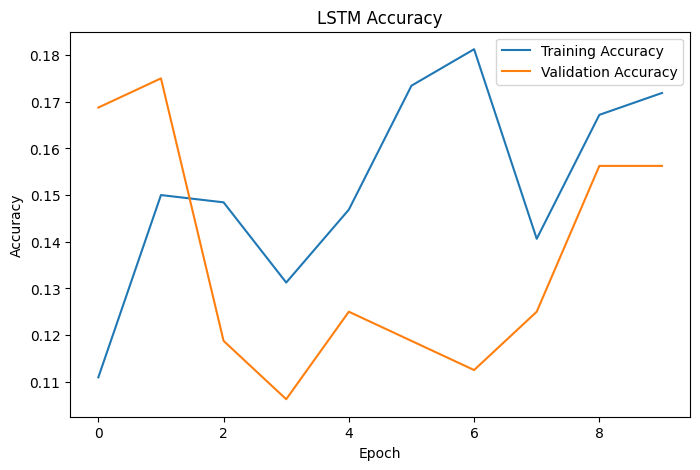

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Accuracy")
plt.legend()
plt.show()

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step 


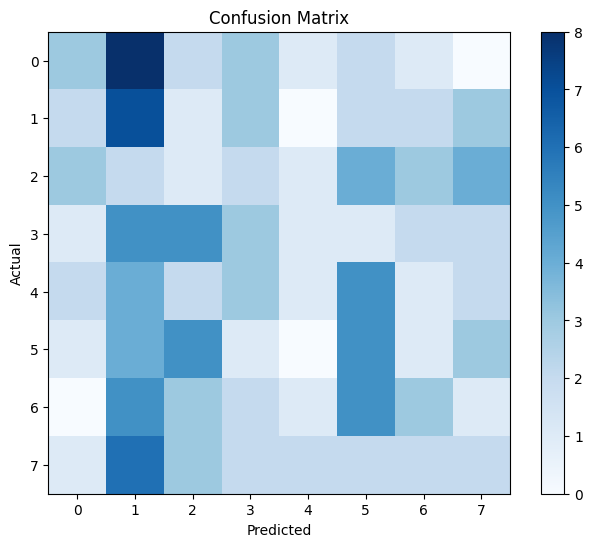

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
y_pred = lstm_model.predict(X_test)
y_pred = y_pred.argmax(axis=1)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [22]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

              precision    recall  f1-score   support

        down       0.23      0.15      0.18        20
          go       0.17      0.35      0.23        20
        left       0.05      0.05      0.05        20
          no       0.16      0.15      0.15        20
       right       0.14      0.05      0.07        20
        stop       0.19      0.25      0.22        20
          up       0.20      0.15      0.17        20
         yes       0.12      0.10      0.11        20

    accuracy                           0.16       160
   macro avg       0.16      0.16      0.15       160
weighted avg       0.16      0.16      0.15       160

